In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 120)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)


## Load the two files

In [2]:
offices = pd.read_csv(DATA_DIR / "Dataset1_Arizona_Dental_Offices.csv")
enrollment = pd.read_csv(
    DATA_DIR / "Dataset2_ACSDT1Y2022.B14007-2025-02-20T031751.csv",
    encoding="utf-8-sig",
)

# Stable id. The city cache uses this same row number.
offices["Office_Id"] = offices.index

print("offices", offices.shape)
print("enrollment places", enrollment.shape[0])
offices.head(3)


offices (3000, 9)
enrollment places 43


,Name,Description,Website,Avg_Review,Num_Reviews,Num_Dentists,Latitude,Longitude,Office_Id
0,Grand Canyon Dental - Elite,"Grand Canyon Dental - Elite in Tucson - From teeth whitening to implants, we offer a full spectrum of dental services to enhance your sm...",https://grandcanyondental.com,4.2,2445,12,32.212878,-110.984568,0
1,Grand Canyon Dental - West,"Grand Canyon Dental - West - We specialize in pediatric dentistry, providing gentle and fun dental care for children of all ages.",https://grandcanyondental.com,4.6,163,13,33.601953,-112.243914,1
2,Desert Valley Dental - Central,"Desert Valley Dental - Central in Phoenix - From teeth whitening to implants, we offer a full spectrum of dental services to enhance you...",https://desertvalleydental.com,2.7,3038,15,33.451326,-112.090552,2


## Brand and pediatric flag

Brand is the text before ` - `. Pediatric means the description has pediatric, kids, children, or child. Family alone does not count. The four biggest brands are set aside before scoring.


In [3]:
offices["Brand"] = offices["Name"].str.split(" - ").str[0].str.strip()

description = offices["Description"].str.lower()
offices["Is_Pediatric"] = description.str.contains(r"pediatric|kids|\bchildren\b|\bchild\b", regex=True)

brand_locations = (
    offices.groupby("Brand", as_index=False)
    .agg(
        Locations=("Office_Id", "size"),
        Pediatric_Offices=("Is_Pediatric", "sum"),
        Avg_Review=("Avg_Review", "mean"),
        Median_Dentists=("Num_Dentists", "median"),
    )
    .sort_values("Locations", ascending=False)
)

major_brands = brand_locations["Brand"].head(4).tolist()
offices["Is_Major"] = offices["Brand"].isin(major_brands)

offices["Office_Group"] = np.select(
    [
        offices["Is_Major"] & offices["Is_Pediatric"],
        offices["Is_Major"] & ~offices["Is_Pediatric"],
        ~offices["Is_Major"] & offices["Is_Pediatric"],
    ],
    [
        "Top-4 brand, pediatric",
        "Top-4 brand, other",
        "Other brand, pediatric",
    ],
    default="Other brand, other",
)

print("pediatric offices:", int(offices["Is_Pediatric"].sum()))
print("pediatric offices inside the top 4 brands:", int((offices["Is_Pediatric"] & offices["Is_Major"]).sum()))
print("pediatric offices eligible on brand:", int((offices["Is_Pediatric"] & ~offices["Is_Major"]).sum()))
print("major brands:", major_brands)


pediatric offices: 480
pediatric offices inside the top 4 brands: 157
pediatric offices eligible on brand: 323
major brands: ['Desert Valley Dental', 'Sunrise Family Dental', 'Arizona Smile Centers', 'Grand Canyon Dental']


## Top 4 brands

In [4]:
top4 = brand_locations.head(4).copy()
top4["Avg_Review"] = top4["Avg_Review"].round(2)
top4


,Brand,Locations,Pediatric_Offices,Avg_Review,Median_Dentists
11,Desert Valley Dental,294,47,3.85,13.0
113,Sunrise Family Dental,272,32,3.76,12.0
0,Arizona Smile Centers,248,45,3.70,12.5
35,Grand Canyon Dental,236,33,3.76,12.0


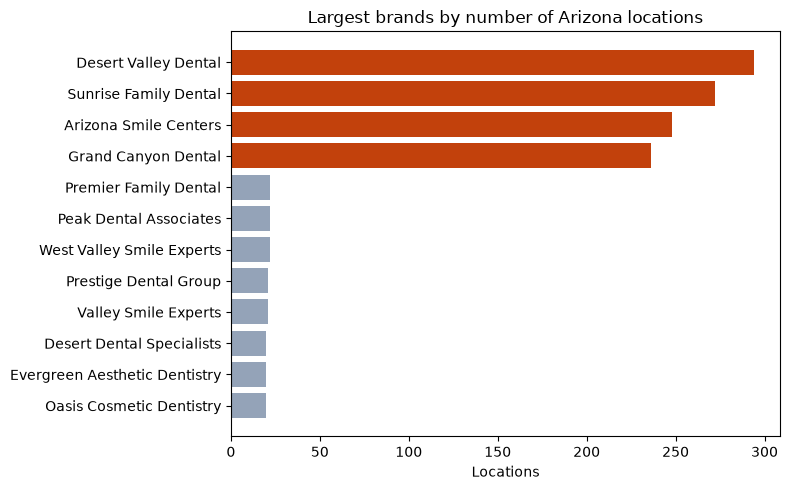

In [5]:
plot_brands = brand_locations.head(12).iloc[::-1]
colors = ["#c2410c" if brand in major_brands else "#94a3b8" for brand in plot_brands["Brand"]]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_brands["Brand"], plot_brands["Locations"], color=colors)
ax.set_xlabel("Locations")
ax.set_title("Largest brands by number of Arizona locations")
fig.tight_layout()
plt.show()


## Spot-check the pediatric flag


In [6]:
pediatric_sample = offices.loc[offices["Is_Pediatric"], ["Name", "Description"]].sample(8, random_state=7)
other_sample = offices.loc[
    ~offices["Is_Pediatric"]
    & offices["Description"].str.contains("family|orthodont|general", case=False),
    ["Name", "Description"],
].sample(8, random_state=7)

print("Called pediatric")
display(pediatric_sample)
print("Not called pediatric")
display(other_sample)


Called pediatric


,Name,Description
776,Sunrise Family Dental - Downtown,"Sunrise Family Dental - Downtown - With specialized pediatric dentists, we focus on preventive care and education to build lifelong heal..."
2828,Desert Dental Associates,Desert Dental Associates - Our team of pediatric dental experts ensures your child has a positive and engaging dental experience.
2845,Peak Advanced Dental Care,"Peak Advanced Dental Care - Dedicated to children's oral health, we offer preventive care, braces, and early intervention treatments."
2410,Grand Canyon Cosmetic Dentistry,Grand Canyon Cosmetic Dentistry - Our mission is to provide top-tier dental care for children while making every visit enjoyable and edu...
1920,Grand Canyon Aesthetic Dentistry,Grand Canyon Aesthetic Dentistry - Our team of pediatric dental experts ensures your child has a positive and engaging dental experience.
2886,Oasis Dental Associates,Oasis Dental Associates - Our mission is to provide top-tier dental care for children while making every visit enjoyable and educational.
783,Sunrise Family Dental - South,"Sunrise Family Dental - South - We specialize in pediatric dentistry, providing gentle and fun dental care for children of all ages."
940,Sunrise Family Dental - Central,Sunrise Family Dental - Central - Our team of pediatric dental experts ensures your child has a positive and engaging dental experience.


Not called pediatric


,Name,Description
2767,Prestige Aesthetic Dentistry,"Prestige Aesthetic Dentistry in Surprise - Our skilled dentists specialize in cosmetic and general dentistry, offering modern solutions ..."
2030,Elite Dental Specialists,"Elite Dental Specialists in Surprise - We specialize in patient-centered care, offering everything from routine cleanings to advanced or..."
1128,West Valley Dental & Orthodontics,"West Valley Dental & Orthodontics in Peoria - We specialize in patient-centered care, offering everything from routine cleanings to adva..."
1874,Pinnacle Dental & Orthodontics,Pinnacle Dental & Orthodontics in Scottsdale - Our highly trained professionals are committed to ensuring healthy and beautiful smiles f...
2998,Valley Aesthetic Dentistry,"Valley Aesthetic Dentistry in Chandler - Our skilled dentists specialize in cosmetic and general dentistry, offering modern solutions fo..."
1863,Pinnacle Dental Specialists,"Pinnacle Dental Specialists in Tempe - Our skilled dentists specialize in cosmetic and general dentistry, offering modern solutions for ..."
1180,Summit Dental Associates,"Summit Dental Associates in Peoria - We specialize in patient-centered care, offering everything from routine cleanings to advanced orth..."
2945,West Valley Cosmetic Dentistry,"West Valley Cosmetic Dentistry in Mesa - Our state-of-the-art facility is equipped to handle general dentistry, cosmetic enhancements, a..."


## Child enrollment

Preschool through grade 12. Some place populations look too big, so check those before scoring.


In [8]:
grade_columns = ["Enrolled in kindergarten"] + [f"Enrolled in grade {i}" for i in range(1, 13)]
enrollment["Child_Enrollment"] = (
    enrollment["Enrolled in nursery school preschool"] + enrollment[grade_columns].sum(axis=1)
)

enrollment_check = enrollment[["Label (Grouping)", "Total", "Child_Enrollment"]].sort_values(
    "Total", ascending=False
)
enrollment_check


,Label (Grouping),Total,Child_Enrollment
19,Sierra Vista,3013902,723739
27,El Mirage,2847005,667228
38,Williamson,2718047,641471
24,South Tucson,2681957,627584
35,Taylor,2302439,472589
28,Desert Hills,2248459,368862
30,Mountainaire,2244430,437507
37,Youngtown,1831417,345959
36,Paradise Valley,1682982,360241
42,Sun CDP,1650598,382837


## Census population check

Keep a place when the file total is between half and twice the Census number. Otherwise set it aside.


In [9]:
cities = pd.read_csv(DATA_DIR / "reference" / "census_az_city_town_pop_2022.csv")
cdps = pd.read_csv(DATA_DIR / "reference" / "census_az_cdp_pop_2020.csv")

cities["Place_Key"] = cities["NAME"].str.replace(r" (city|town|village)$", "", regex=True).str.lower()
cdps["Place_Key"] = cdps["BASENAME"].str.lower().str.strip()
cdps["POP100"] = pd.to_numeric(cdps["POP100"], errors="coerce")

reference = pd.concat(
    [
        cities.rename(columns={"POPESTIMATE2022": "Census_Population"})[["Place_Key", "Census_Population"]].assign(
            Census_Source="2022 city and town estimate"
        ),
        cdps.rename(columns={"POP100": "Census_Population"})[["Place_Key", "Census_Population"]].assign(
            Census_Source="2020 census designated place count"
        ),
    ],
    ignore_index=True,
)
reference = reference.drop_duplicates("Place_Key", keep="first")

aliases = {"stotonic": "stotonic village"}

population_check = enrollment[["Label (Grouping)", "Total", "Child_Enrollment"]].copy()
population_check["Place_Key"] = (
    population_check["Label (Grouping)"]
    .str.replace(r"\s+cdp$", "", regex=True, case=False)
    .str.lower()
    .str.strip()
    .replace(aliases)
)
population_check = population_check.merge(reference, on="Place_Key", how="left")
population_check["File_To_Census_Ratio"] = population_check["Total"] / population_check["Census_Population"]

same_size = population_check["File_To_Census_Ratio"].between(0.5, 2)
population_check["Market_Data"] = "Set aside"
population_check.loc[same_size, "Market_Data"] = "Keep"

population_check = population_check.sort_values(
    ["Market_Data", "File_To_Census_Ratio"],
    ascending=[True, False],
)

print(population_check["Market_Data"].value_counts().to_string())
population_check.to_csv(OUTPUT_DIR / "enrollment_population_check.csv", index=False)

show = population_check[
    ["Label (Grouping)", "Total", "Census_Population", "File_To_Census_Ratio", "Census_Source", "Market_Data"]
].copy()
show["File_To_Census_Ratio"] = show["File_To_Census_Ratio"].round(2)
show


Market_Data
Set aside    24
Keep         19


,Label (Grouping),Total,Census_Population,File_To_Census_Ratio,Census_Source,Market_Data
13,San Tan Valley CDP,114495,99894.0,1.15,2020 census designated place count,Keep
2,Casas Adobes CDP,72837,70973.0,1.03,2020 census designated place count,Keep
4,Flagstaff,74745,75907.0,0.98,2022 city and town estimate,Keep
14,Scottsdale,238498,243050.0,0.98,2022 city and town estimate,Keep
7,Goodyear,103251,105406.0,0.98,2022 city and town estimate,Keep
8,Maricopa,64924,66290.0,0.98,2022 city and town estimate,Keep
16,Tempe,181400,185950.0,0.98,2022 city and town estimate,Keep
10,Peoria,192528,197866.0,0.97,2022 city and town estimate,Keep
3,Chandler,271902,280711.0,0.97,2022 city and town estimate,Keep
17,Tucson,529127,546574.0,0.97,2022 city and town estimate,Keep


## Range checks

Ratings, dentist counts, coordinates, and whether the enrollment parts add up.


In [10]:
print("rating outside 1 to 5:", int((~offices["Avg_Review"].between(1, 5)).sum()))
print("review count negative:", int((offices["Num_Reviews"] < 0).sum()))
print("dentist count below 1:", int((offices["Num_Dentists"] < 1).sum()))
print("coordinates outside Arizona:", int((
    ~offices["Latitude"].between(31, 37) | ~offices["Longitude"].between(-115, -109)
).sum()))

grade_columns = ["Enrolled in kindergarten"] + [f"Enrolled in grade {i}" for i in range(1, 13)]
detail_columns = ["Enrolled in nursery school preschool", *grade_columns, "Enrolled in college undergraduate years", "Graduate or professional school"]
parts_match = (
    enrollment[detail_columns].sum(axis=1).eq(enrollment["Enrolled in school"])
    & enrollment["Enrolled in school"].add(enrollment["Not enrolled in school"]).eq(enrollment["Total"])
)
print("enrollment rows whose parts add up:", int(parts_match.sum()), "of", len(enrollment))


rating outside 1 to 5: 0
review count negative: 0
dentist count below 1: 0
coordinates outside Arizona: 0
enrollment rows whose parts add up: 43 of 43


## Attach city

Score only places that passed the population check. Kids per office still counts the top 4 brands in that city.


In [11]:
geo = pd.read_csv(OUTPUT_DIR / "geocode_cache.csv")
if geo["Office_Id"].nunique() < len(offices):
    raise RuntimeError(
        f"City cache has {geo['Office_Id'].nunique()} offices, expected {len(offices)}. "
        "Run geocode_cities.py until it finishes."
    )

offices = offices.merge(geo[["Office_Id", "City_Raw"]], on="Office_Id", how="left")
offices["Place_Key"] = (
    offices["City_Raw"]
    .fillna("")
    .str.lower()
    .str.strip()
    .str.replace(r"^city of\s+", "", regex=True)
    .str.replace(r"\s+cdp$", "", regex=True)
    .replace({"stotonic": "stotonic village"})
)
offices.loc[offices["Place_Key"].eq(""), "Place_Key"] = pd.NA

keep_places = population_check.loc[
    population_check["Market_Data"].eq("Keep"),
    ["Place_Key", "Label (Grouping)", "Child_Enrollment"],
].rename(columns={"Label (Grouping)": "Enrollment_Place"})

offices = offices.merge(keep_places, on="Place_Key", how="left")
offices["City_Usable"] = offices["Child_Enrollment"].notna()

pediatric_in_city = (
    offices.loc[offices["Is_Pediatric"] & offices["City_Usable"]]
    .groupby("Place_Key")
    .size()
    .rename("Pediatric_Offices_In_City")
)
offices = offices.merge(pediatric_in_city, on="Place_Key", how="left")
offices["Kids_Per_Pediatric_Office"] = (
    offices["Child_Enrollment"] / offices["Pediatric_Offices_In_City"]
)

candidates = offices.loc[offices["Is_Pediatric"] & ~offices["Is_Major"]].copy()
print("pediatric offices outside the top 4 brands:", len(candidates))
print("of those, in a city with usable enrollment:", int(candidates["City_Usable"].sum()))
print("offices with no city name:", int(offices["City_Raw"].isna().sum()))
print("top cities among candidates that cannot be scored:")
print(
    candidates.loc[~candidates["City_Usable"], "City_Raw"]
    .fillna("(no city)")
    .value_counts()
    .head(12)
    .to_string()
)


pediatric offices outside the top 4 brands: 323
of those, in a city with usable enrollment: 157
offices with no city name: 651
top cities among candidates that cannot be scored:
City_Raw
(no city)              106
Sierra Vista            11
Lake Havasu City         9
Prescott                 7
Taylor                   6
Paradise Valley          6
Sun City                 2
Lone Butte Ranch         2
Cocopah                  2
San Xavier District      2
Whipple                  2
Groom Creek              1


## Miles to the nearest pediatric office

Shown on the list. Not in the score.


In [12]:
pediatric_points = offices.loc[
    offices["Is_Pediatric"], ["Office_Id", "Latitude", "Longitude"]
].reset_index(drop=True)

lat = np.radians(pediatric_points["Latitude"].to_numpy())
lon = np.radians(pediatric_points["Longitude"].to_numpy())
lat_gap = lat[:, None] - lat[None, :]
lon_gap = lon[:, None] - lon[None, :]
haversine = np.sin(lat_gap / 2) ** 2 + np.cos(lat)[:, None] * np.cos(lat)[None, :] * np.sin(lon_gap / 2) ** 2
miles = 2 * 3958.8 * np.arcsin(np.sqrt(np.clip(haversine, 0, 1)))
np.fill_diagonal(miles, np.inf)
pediatric_points["Miles_To_Nearest_Pediatric"] = miles.min(axis=1)

offices = offices.merge(
    pediatric_points[["Office_Id", "Miles_To_Nearest_Pediatric"]],
    on="Office_Id",
    how="left",
)
candidates = candidates.merge(
    pediatric_points[["Office_Id", "Miles_To_Nearest_Pediatric"]],
    on="Office_Id",
    how="left",
)


## Score the top 50

Equal-weight percentiles: child enrollment, kids per office, review-adjusted rating, dentist count.


In [13]:
def add_score(frame, weights):
    scored = frame.copy()
    review_anchor = scored["Num_Reviews"].median()
    rating_center = scored["Avg_Review"].mean()
    reviews = scored["Num_Reviews"]
    scored["Rating_Adjusted"] = (
        (reviews / (reviews + review_anchor)) * scored["Avg_Review"]
        + (review_anchor / (reviews + review_anchor)) * rating_center
    )
    enrollment_weight, kids_weight, rating_weight, dentist_weight = weights
    scored["Score"] = (
        enrollment_weight * scored["Child_Enrollment"].rank(pct=True)
        + kids_weight * scored["Kids_Per_Pediatric_Office"].rank(pct=True)
        + rating_weight * scored["Rating_Adjusted"].rank(pct=True)
        + dentist_weight * scored["Num_Dentists"].rank(pct=True)
    )
    return scored.sort_values(["Score", "Office_Id"], ascending=[False, True])


base_weights = (0.25, 0.25, 0.25, 0.25)
scoreable = candidates.loc[candidates["City_Usable"]].copy()
ranked = add_score(scoreable, base_weights)
top50 = ranked.head(50).copy()
top50["Rank"] = range(1, len(top50) + 1)

print("candidates scored:", len(ranked))
print("median reviews used as the anchor:", int(scoreable["Num_Reviews"].median()))
print("brands in the top 50:", top50["Brand"].nunique())

top50_view = top50[
    [
        "Rank",
        "Name",
        "Brand",
        "City_Raw",
        "Avg_Review",
        "Num_Reviews",
        "Rating_Adjusted",
        "Num_Dentists",
        "Child_Enrollment",
        "Pediatric_Offices_In_City",
        "Kids_Per_Pediatric_Office",
        "Miles_To_Nearest_Pediatric",
        "Score",
    ]
].copy()
top50_view["Rating_Adjusted"] = top50_view["Rating_Adjusted"].round(2)
top50_view["Kids_Per_Pediatric_Office"] = top50_view["Kids_Per_Pediatric_Office"].round(0)
top50_view["Miles_To_Nearest_Pediatric"] = top50_view["Miles_To_Nearest_Pediatric"].round(1)
top50_view["Score"] = top50_view["Score"].round(3)
top50_view


candidates scored: 157
median reviews used as the anchor: 1862
brands in the top 50: 43


,Rank,Name,Brand,City_Raw,Avg_Review,Num_Reviews,Rating_Adjusted,Num_Dentists,Child_Enrollment,Pediatric_Offices_In_City,Kids_Per_Pediatric_Office,Miles_To_Nearest_Pediatric,Score
309,1,Sunset Family Dental,Sunset Family Dental,Phoenix,4.7,4746,4.43,9,299034.0,80.0,3738.0,1.8,0.844
204,2,Valley Family Dental,Valley Family Dental,Gilbert,4.7,1877,4.22,9,62309.0,11.0,5664.0,1.6,0.833
57,3,Desert Aesthetic Dentistry,Desert Aesthetic Dentistry,Phoenix,4.7,4578,4.42,8,299034.0,80.0,3738.0,0.7,0.818
103,4,Desert Dental Group,Desert Dental Group,Phoenix,4.1,4096,3.98,9,299034.0,80.0,3738.0,0.9,0.801
55,5,Desert Family Dental,Desert Family Dental,Phoenix,4.7,1030,4.07,8,299034.0,80.0,3738.0,0.7,0.791
37,6,Sunset Dental Specialists,Sunset Dental Specialists,Gilbert,4.1,2560,3.94,8,62309.0,11.0,5664.0,0.4,0.777
4,7,Summit Family Dental,Summit Family Dental,Phoenix,3.9,2998,3.83,8,299034.0,80.0,3738.0,0.9,0.745
161,8,Pinnacle Dental & Orthodontics,Pinnacle Dental & Orthodontics,Phoenix,4.5,288,3.83,8,299034.0,80.0,3738.0,1.6,0.742
229,9,Grand Canyon Aesthetic Dentistry,Grand Canyon Aesthetic Dentistry,Mesa,3.9,2873,3.83,7,94171.0,19.0,4956.0,0.6,0.738
218,10,Premier Dental Group,Premier Dental Group,Phoenix,4.0,3669,3.91,7,299034.0,80.0,3738.0,0.7,0.732


## Brand slots and close scores


In [14]:
brand_slots = (
    top50.groupby("Brand", as_index=False)
    .size()
    .rename(columns={"size": "Slots_In_Top_50"})
    .sort_values(["Slots_In_Top_50", "Brand"], ascending=[False, True])
)
brand_slots


,Brand,Slots_In_Top_50
13,Horizon Aesthetic Dentistry,2
17,Oasis Dental & Orthodontics,2
22,Peak Family Dental,2
26,Pinnacle Dental Specialists,2
30,Premier Dental Associates,2
37,Sunset Dental Specialists,2
38,Sunset Family Dental,2
0,Desert Aesthetic Dentistry,1
1,Desert Dental Group,1
2,Desert Family Dental,1


In [15]:
ranked_top = top50.sort_values("Rank")
score_gap = ranked_top["Score"].diff(-1).abs()
close_ranks = ranked_top.loc[score_gap.lt(0.01), "Rank"]
close_pair_ranks = sorted(set(close_ranks.tolist()) | set((close_ranks + 1).tolist()))
close_pairs = ranked_top.loc[
    ranked_top["Rank"].isin(close_pair_ranks),
    ["Rank", "Name", "City_Raw", "Score", "Miles_To_Nearest_Pediatric"],
].copy()
close_pairs["Score"] = close_pairs["Score"].round(3)
close_pairs["Miles_To_Nearest_Pediatric"] = close_pairs["Miles_To_Nearest_Pediatric"].round(1)

if close_pairs.empty:
    print("No adjacent offices in the top 50 have scores within 0.01.")
else:
    print("Adjacent offices whose scores differ by less than 0.01:")
close_pairs


Adjacent offices whose scores differ by less than 0.01:


,Rank,Name,City_Raw,Score,Miles_To_Nearest_Pediatric
103,4,Desert Dental Group,Phoenix,0.801,0.9
55,5,Desert Family Dental,Phoenix,0.791,0.7
4,7,Summit Family Dental,Phoenix,0.745,0.9
161,8,Pinnacle Dental & Orthodontics,Phoenix,0.742,1.6
229,9,Grand Canyon Aesthetic Dentistry,Mesa,0.738,0.6
218,10,Premier Dental Group,Phoenix,0.732,0.7
82,11,Horizon Aesthetic Dentistry,Gilbert,0.730,0.4
206,12,Pinnacle Smile Experts,Phoenix,0.726,1.4
130,13,Horizon Aesthetic Dentistry,Phoenix,0.725,2.2
54,14,Peak Oral Care,Phoenix,0.718,0.3


## Sensitivity

Market-heavy weights, quality-heavy weights, and brands under 15 locations.


In [16]:
def top_ids(frame, weights):
    return set(add_score(frame, weights).head(50)["Office_Id"])


base_ids = set(top50["Office_Id"])
market_ids = top_ids(scoreable, (0.35, 0.35, 0.15, 0.15))
quality_ids = top_ids(scoreable, (0.15, 0.15, 0.35, 0.35))

location_counts = offices.groupby("Brand").size()
smaller_brands = scoreable.loc[scoreable["Brand"].map(location_counts).lt(15)].copy()
smaller_ids = top_ids(smaller_brands, base_weights)

sensitivity = pd.DataFrame(
    {
        "Check": [
            "Market-heavy weights",
            "Quality-heavy weights",
            "Brands with fewer than 15 locations",
        ],
        "Offices_Still_In_Top_50": [
            len(base_ids & market_ids),
            len(base_ids & quality_ids),
            len(base_ids & smaller_ids),
        ],
        "Candidates_Scored": [
            len(scoreable),
            len(scoreable),
            len(smaller_brands),
        ],
    }
)
sensitivity


,Check,Offices_Still_In_Top_50,Candidates_Scored
0,Market-heavy weights,46,157
1,Quality-heavy weights,35,157
2,Brands with fewer than 15 locations,22,78


## Export


In [17]:
offices["Is_Top_50"] = offices["Office_Id"].isin(base_ids)
offices["Score"] = offices["Office_Id"].map(ranked.set_index("Office_Id")["Score"])
offices["Rating_Adjusted"] = offices["Office_Id"].map(ranked.set_index("Office_Id")["Rating_Adjusted"])

export_columns = [
    "Office_Id",
    "Name",
    "Brand",
    "Description",
    "Website",
    "Avg_Review",
    "Num_Reviews",
    "Rating_Adjusted",
    "Num_Dentists",
    "Latitude",
    "Longitude",
    "Is_Pediatric",
    "Is_Major",
    "Office_Group",
    "City_Raw",
    "Enrollment_Place",
    "City_Usable",
    "Child_Enrollment",
    "Pediatric_Offices_In_City",
    "Kids_Per_Pediatric_Office",
    "Miles_To_Nearest_Pediatric",
    "Score",
    "Is_Top_50",
]
offices[export_columns].to_csv(OUTPUT_DIR / "offices_enriched.csv", index=False)
top50_view.to_csv(OUTPUT_DIR / "top50_candidates.csv", index=False)
brand_slots.to_csv(OUTPUT_DIR / "top50_brand_counts.csv", index=False)
top4.to_csv(OUTPUT_DIR / "top4_competitors.csv", index=False)
sensitivity.to_csv(OUTPUT_DIR / "score_sensitivity.csv", index=False)
print("wrote files to", OUTPUT_DIR)


wrote files to output


## Notes

Screen, not a price. Bad population rows and cities outside the kept places stay off the list. Price, profit, and willingness to sell are not in the score.
